In [1]:
# import dependencies
import os
import random
import numpy as np
import pandas as pd
import cell2cell as c2c
import scanpy as sc
import loompy as lp
#from MulticoreTSNE import MulticoreTSNE as TSNE
from multiprocessing import cpu_count
from ctxcore.genesig import GeneSignature

from sklearn.metrics import silhouette_samples, silhouette_score

import warnings
warnings.filterwarnings('ignore')

/oceanus/collab/InternalJeff/users/gxm300/anaconda3/envs/pyscenic_stable/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cpu_cnt = cpu_count()
cpu_cnt

80

In [3]:
# set variables for file paths to read from and write to:

# set a working directory
wdir = "/oceanus/collab/APLIN_LAB/Data/Public/scRNAseq/Izar_scRNAseq"
os.chdir( wdir )

# path to mtx file
f_mtx = "GSE200218_sc_sn_counts.mtx"

# path to var gene names
f_genes = "GSE200218_sc_sn_gene_names.csv"

# path to obs data
f_obs = "GSE200218_sc_sn_metadata.csv"

# path to unfiltered loom file (this will be created in the optional steps below)
f_loom_path_unfilt = "Izar_scRNAseq_unfiltered.loom" # test dataset, n=500 cells

# # path to loom file with basic filtering applied (this will be created in the "initial filtering" step below). Optional.
f_loom_path_scenic = "Izar_scRNAseq_filtered_scenic.loom"

# path to anndata object, which will be updated to store Scanpy results as they are generated below
f_anndata_path = "Izar_scRNAseq_anndata.h5ad"

# path to pyscenic output
f_pyscenic_output = "Izar_scRNAseq_pyscenic_output.loom"

# loom output, generated from a combination of Scanpy and pySCENIC results:
f_final_loom = 'Izar_scRNAseq_scenic_integrated-output.loom'

In [4]:
sc.settings.verbosity = 3 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
sc.set_figure_params(dpi=150, fontsize=10, dpi_save=600)

-----
anndata     0.8.0
scanpy      1.9.3
-----
PIL                 9.4.0
attr                24.2.0
backcall            0.2.0
beta_ufunc          NA
binom_ufunc         NA
bottleneck          1.3.5
cairo               1.21.0
cell2cell           0.7.3
cffi                1.15.1
cloudpickle         2.2.1
colorama            0.4.6
ctxcore             0.2.0
cycler              0.10.0
cython_runtime      NA
cytoolz             0.12.3
dask                2022.02.0
dateutil            2.9.0
debugpy             1.6.3
decorator           5.1.1
defusedxml          0.7.1
entrypoints         0.4
frozendict          2.4.7
fsspec              2023.1.0
h5py                3.7.0
igraph              0.7.1
ipykernel           6.16.2
ipython_genutils    0.2.0
jedi                0.19.1
jinja2              3.1.4
joblib              1.3.2
kiwisolver          1.4.4
kneed               0.8.5
leidenalg           0.8.3
llvmlite            0.39.1
loompy              3.0.8
louvain             0.7.0
markupsafe  

In [5]:
# Set maximum number of jobs for Scanpy.
sc.settings.njobs = cpu_cnt

# Expression data import

## Reading in data from multiple files and merging into adata object 

In [6]:
# Load in mtx to serve as initial adata object
adata = sc.read_mtx(f_mtx)
adata = adata.transpose()

In [7]:
adata

AnnData object with n_obs × n_vars = 145555 × 35652

In [8]:
gene_names = pd.read_csv(f_genes)
gene_names.columns = ["gene_names"]

In [9]:
adata.var_names = gene_names["gene_names"]

In [10]:
adata.var

""
gene_names
AL627309.1
AL627309.5
AP006222.2
LINC01409
FAM87B
...
AC087477.4
AC005789.1
BX640514.1


In [11]:
meta = pd.read_csv(f_obs)
meta = meta.rename(columns={'Unnamed: 0': 'Cell'})

In [12]:
adata.obs = meta.drop(["Cell", "nCount_RNA", "nFeature_RNA", "percent.mt", "percent.rps", "percent.rpl", "percent.rp"], axis=1)
adata.obs_names = meta["Cell"]
adata.obs

,orig.ident,barcode,barcode_pat,patient,ID,batch,sequencing,organ,doublet_scores,doublet,...,sample_TRB3,nt_TRB3,cohort_TRB3,disease_TRB3,tcr,both_chains,mait,inkt,mait_inkt,clone_size
Cell,,,,,,,,,,,,,,,,,,,,,
CTCGTACCAAGCTGGA-1_1,MBM01_sc_CD45pos,CTCGTACCAAGCTGGA-1,CTCGTACCAAGCTGGA-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.048314,Singlet,...,NaN,NaN,NaN,NaN,TCR,both,no_MAIT,no_iNKT,no_MAIT;no_iNKT,Non-expanded
AGATTGCAGTGGGTTG-1_1,MBM01_sc_CD45pos,AGATTGCAGTGGGTTG-1,AGATTGCAGTGGGTTG-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.046330,Singlet,...,NaN,NaN,NaN,NaN,TCR,both,no_MAIT,no_iNKT,no_MAIT;no_iNKT,Non-expanded
TCGGGACTCAACACTG-1_1,MBM01_sc_CD45pos,TCGGGACTCAACACTG-1,TCGGGACTCAACACTG-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.054975,Singlet,...,NaN,NaN,NaN,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN
CTCGGAGCAGCTATTG-1_1,MBM01_sc_CD45pos,CTCGGAGCAGCTATTG-1,CTCGGAGCAGCTATTG-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.018009,Singlet,...,NaN,NaN,NaN,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN
TACACGATCAACACAC-1_1,MBM01_sc_CD45pos,TACACGATCAACACAC-1,TACACGATCAACACAC-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.106180,Singlet,...,NaN,NaN,NaN,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TACTGCCCATCGAGCC-1_32,MPM11_sn,TACTGCCCATCGAGCC-1,TACTGCCCATCGAGCC-1_MPM11_sn,MPM11_sn,MPM11,NaN,Single nuclei,Peripheral,0.060541,Singlet,...,NaN,NaN,NaN,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN
GCACGTGTCGTAATGC-1_32,MPM11_sn,GCACGTGTCGTAATGC-1,GCACGTGTCGTAATGC-1_MPM11_sn,MPM11_sn,MPM11,NaN,Single nuclei,Peripheral,0.033597,Singlet,...,NaN,NaN,NaN,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN
ATGGAGGAGTTTGTCG-1_32,MPM11_sn,ATGGAGGAGTTTGTCG-1,ATGGAGGAGTTTGTCG-1_MPM11_sn,MPM11_sn,MPM11,NaN,Single nuclei,Peripheral,0.052060,Singlet,...,NaN,NaN,NaN,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN


# Initial/basic filtering

In [13]:
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D
#import distinctipy

In [14]:
nCountsPerGene = np.sum(adata.X, axis=0)
nCellsPerGene = np.sum(adata.X>0, axis=0)

# Show info
print("Number of counts (in the dataset units) per gene:", nCountsPerGene.min(), " - " ,nCountsPerGene.max())
print("Number of cells in which each gene is detected:", nCellsPerGene.min(), " - " ,nCellsPerGene.max())

Number of counts (in the dataset units) per gene: 0.0  -  27185428.0
Number of cells in which each gene is detected: 0  -  144049


In [15]:
nCells=adata.X.shape[0]

# pySCENIC thresholds
minCountsPerGene=3*.01*nCells # 3 counts in 1% of cells
print("minCountsPerGene: ", minCountsPerGene)

minSamples=.01*nCells # 1% of cells
print("minSamples: ", minSamples)

minCountsPerGene:  4366.65
minSamples:  1455.55


In [16]:
# simply compute the number of genes per cell (computers 'n_genes' column)
sc.pp.filter_cells(adata, min_genes=0)
# mito and genes/counts cuts
mito_genes = adata.var_names.str.startswith('MT-')
# for each cell compute fraction of counts in mito genes vs. all genes
adata.obs['percent_mito'] = np.sum(
    adata[:, mito_genes].X, axis=1).A1 / np.sum(adata.X, axis=1).A1
# add the total counts per cell as observations-annotation to adata
adata.obs['n_counts'] = adata.X.sum(axis=1).A1

# Diagnostic Plots, pre-filtering

### Number of genes expressed per cell

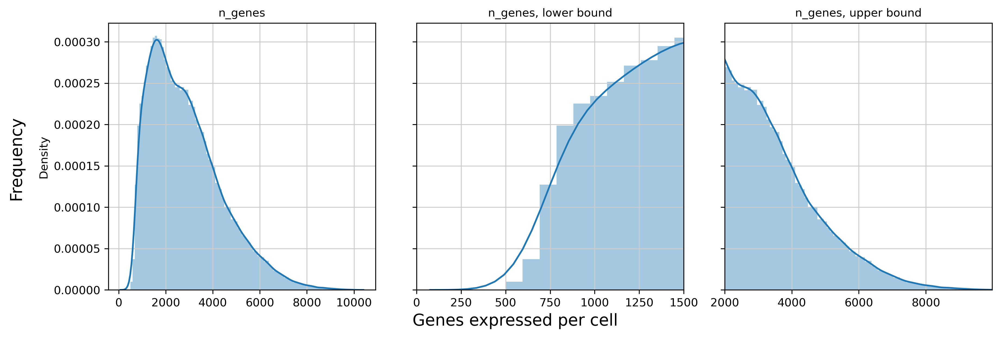

In [17]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['n_genes']
x_lowerbound = 1500
x_upperbound = 2000
nbins=100

sns.distplot(x, ax=ax1, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax2, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax3, norm_hist=True, bins=nbins)

ax2.set_xlim(0,x_lowerbound)
ax3.set_xlim(x_upperbound, adata.obs['n_genes'].max() )

for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('n_genes')
ax2.title.set_text('n_genes, lower bound')
ax3.title.set_text('n_genes, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Genes expressed per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

### Percentage of mitochondrial reads per cell

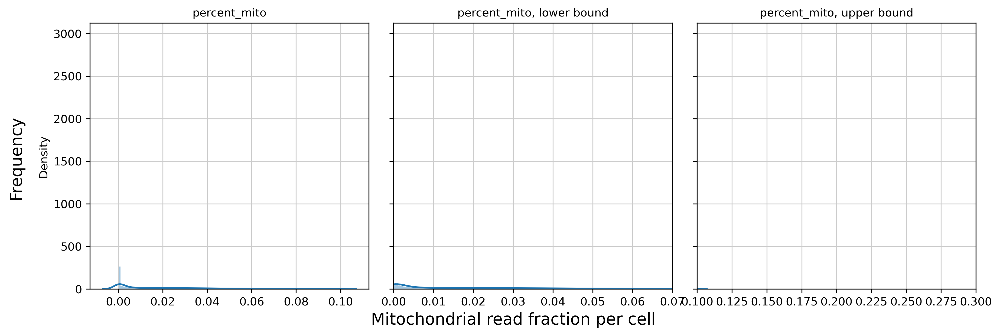

In [18]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['percent_mito']
x_lowerbound = [0.0, 0.07 ]
x_upperbound = [ 0.10, 0.3 ]
nbins=100

sns.distplot(x, ax=ax1, norm_hist=True, bins=nbins)
sns.distplot(x, ax=ax2, norm_hist=True, bins=int(nbins/(x_lowerbound[1]-x_lowerbound[0])) )
sns.distplot(x, ax=ax3, norm_hist=True, bins=int(nbins/(x_upperbound[1]-x_upperbound[0])) )

ax2.set_xlim(x_lowerbound[0], x_lowerbound[1])
ax3.set_xlim(x_upperbound[0], x_upperbound[1] )
for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('percent_mito')
ax2.title.set_text('percent_mito, lower bound')
ax3.title.set_text('percent_mito, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Mitochondrial read fraction per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

### Three panel plot summary

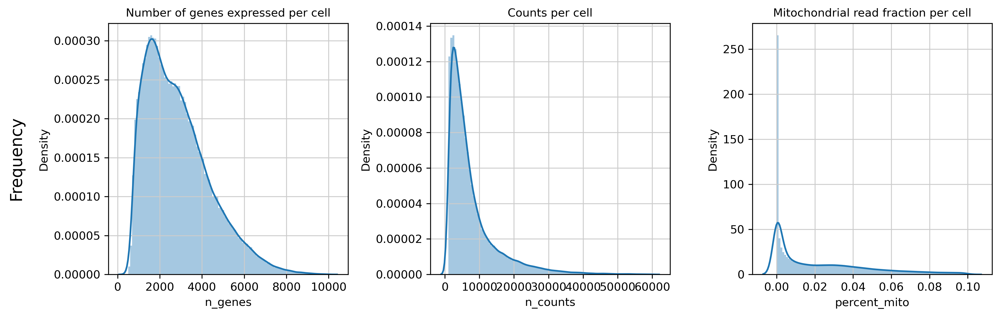

In [19]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

sns.distplot( adata.obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
sns.distplot( adata.obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
sns.distplot( adata.obs['percent_mito'], ax=ax3, norm_hist=True, bins=100)

ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_prefilter.pdf', dpi=600, bbox_inches='tight')

### Per sample 

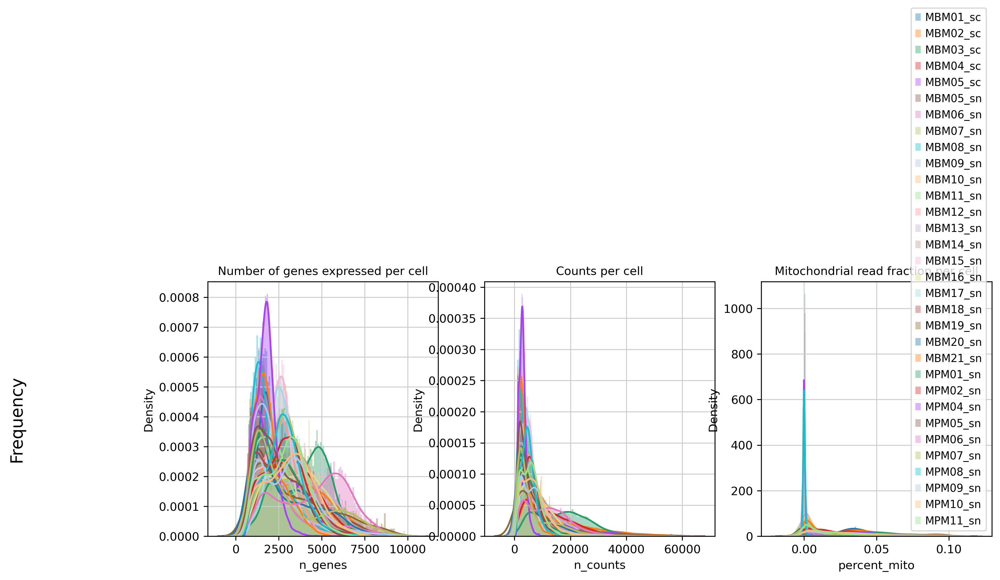

In [20]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

for sample in np.unique(adata.obs.patient): # iterate through each sample ID and plot
    
    sns.distplot( adata[adata.obs.patient == sample].obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.patient == sample].obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.patient == sample].obs['percent_mito'], ax=ax3, norm_hist=True, bins=100, label = sample)
    
ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')
ax3.legend()

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_prefilter_individual.pdf', dpi=600, bbox_inches='tight')

In [21]:
print(adata.var.index.is_unique)
adata.var_names_make_unique()
print(adata.var.index.is_unique)

False
True


In [22]:
adata.raw = adata
print(adata.raw.var.index.is_unique)

True


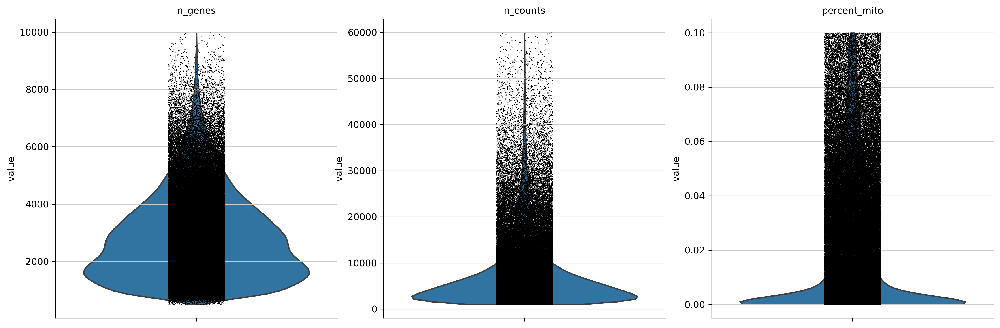

In [23]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], multi_panel = True)

### Scatter plot, n_genes by n_counts

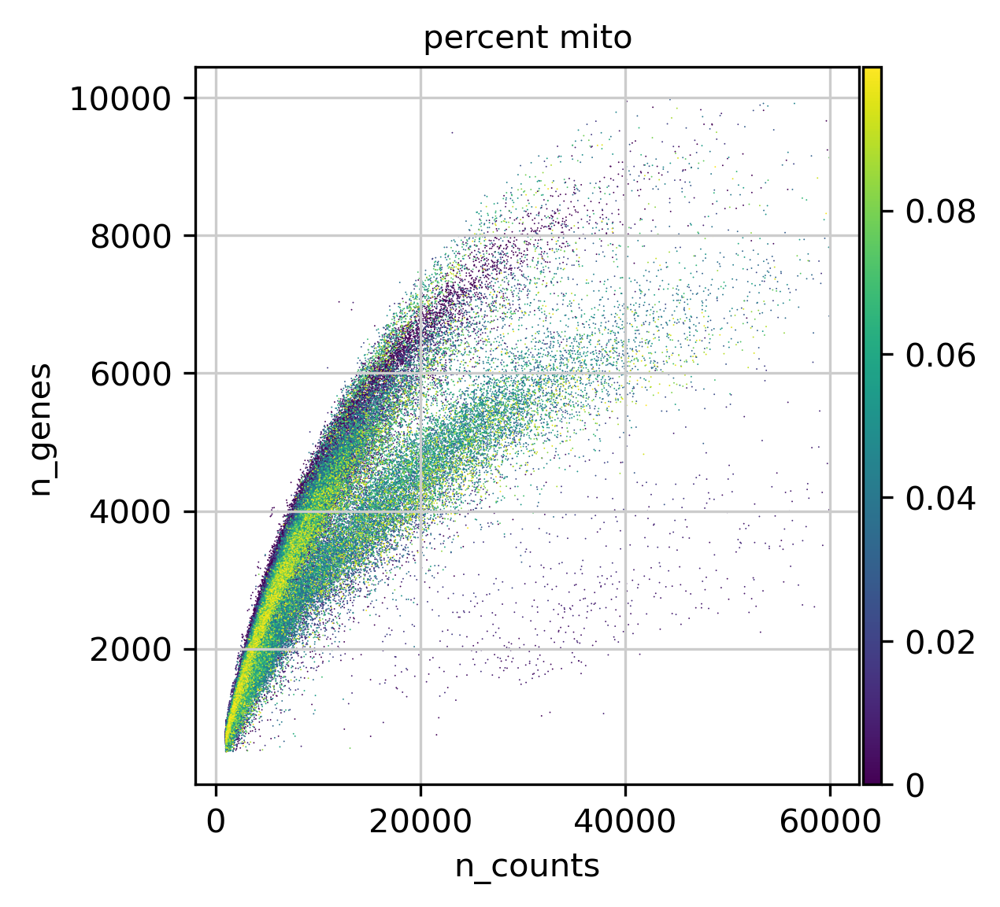

In [24]:
sc.pl.scatter(adata, x='n_counts', y='n_genes', color='percent_mito')

# Carry out filtering steps:

In [25]:
# initial cuts
sc.pp.filter_cells(adata, min_genes=200 )
sc.pp.filter_genes(adata, min_cells=3 )

filtered out 1092 genes that are detected in less than 3 cells


In [26]:
adata = adata[adata.obs['n_genes'] < 7000, :]
adata = adata[adata.obs['percent_mito'] < 0.15, :]

# Diagnostic plots, post filtering

### Three-panel summary plots 

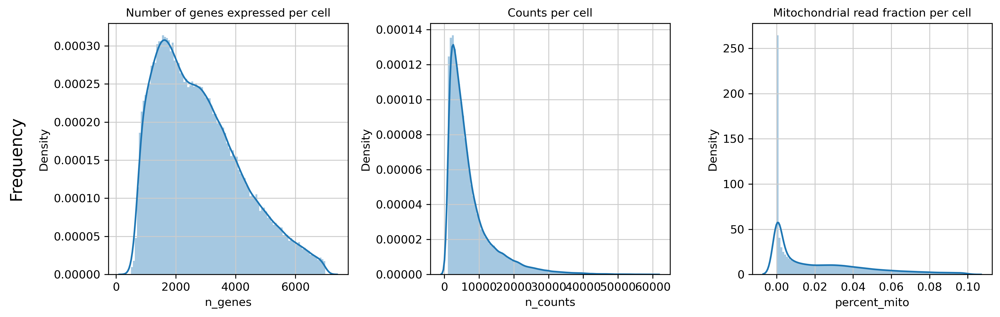

In [27]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

adata.obs['n_genes']

sns.distplot( adata.obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
sns.distplot( adata.obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
sns.distplot( adata.obs['percent_mito'], ax=ax3, norm_hist=True, bins=100)

ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_postfilter.pdf', dpi=600, bbox_inches='tight')

### Per sample 

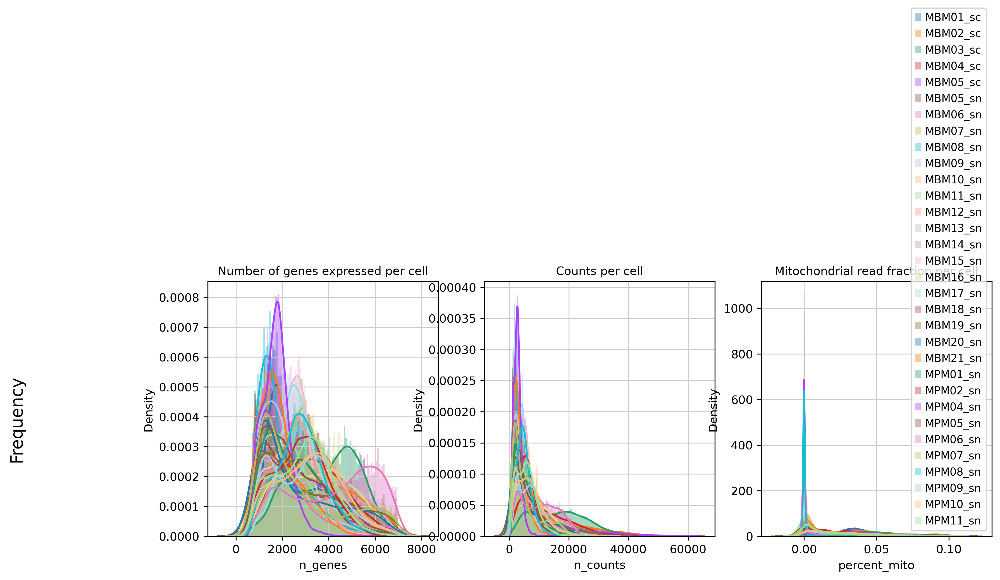

In [28]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)

for sample in np.unique(adata.obs.patient): # iterate through each sample ID and plot
    
    sns.distplot( adata[adata.obs.patient == sample].obs['n_genes'], ax=ax1, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.patient == sample].obs['n_counts'], ax=ax2, norm_hist=True, bins=100)
    sns.distplot( adata[adata.obs.patient == sample].obs['percent_mito'], ax=ax3, norm_hist=True, bins=100, label = sample)
    
ax1.title.set_text('Number of genes expressed per cell')
ax2.title.set_text('Counts per cell')
ax3.title.set_text('Mitochondrial read fraction per cell')
ax3.legend()

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

fig.tight_layout()

fig.savefig('figures/filtering_panel/filtering_panel_postfilter_individual.pdf', dpi=600, bbox_inches='tight')

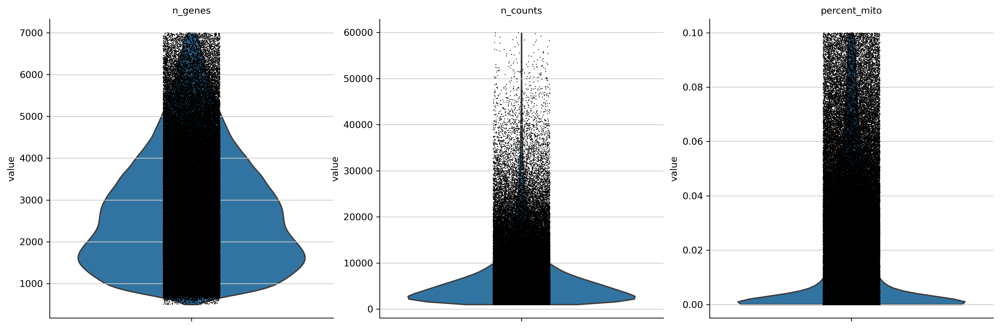

In [29]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], multi_panel = True)

### Scatter plot, n_genes by n_counts 

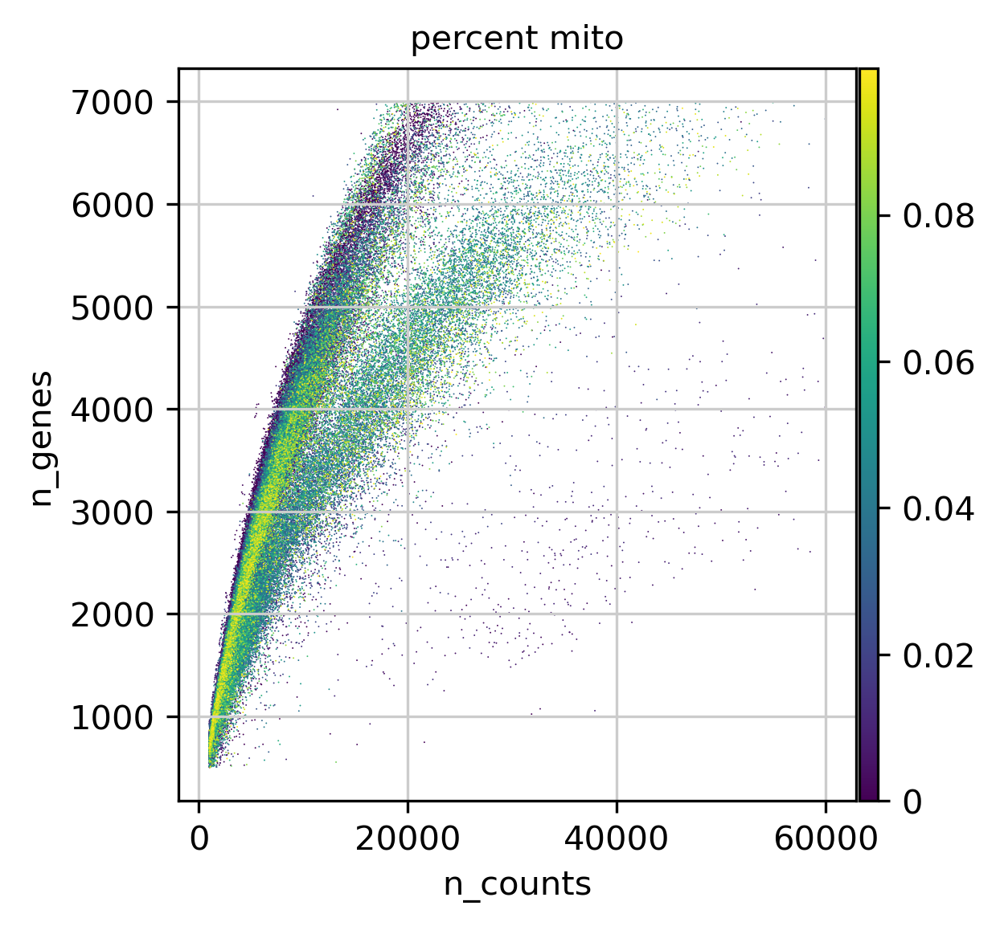

In [30]:
sc.pl.scatter(adata, x='n_counts', y='n_genes', color='percent_mito')

# Finalize the selected filters

Update the anndata file, to be used for further processing, clustering, visualization, etc..



In [31]:
adata.write( f_anndata_path )

# Dot plot of expression values of genes for each signature in a collection 

In [32]:
# save a copy of the raw data
adata.raw = adata

# Total-count normalize (library-size correct) to 10,000 reads/cell
sc.pp.normalize_per_cell(adata, counts_per_cell_after=1e4)

# log transform the data.
sc.pp.log1p(adata)

# regress out total counts per cell and the percentage of mitochondrial genes expressed
sc.pp.regress_out(adata, ['n_counts', 'percent_mito'] ) #, n_jobs=args.threads)

# scale each gene to unit variance, clip values exceeding SD 10.
sc.pp.scale(adata, max_value=10)

normalizing by total count per cell
    finished (0:00:09): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
regressing out ['n_counts', 'percent_mito']
    sparse input is densified and may lead to high memory use
    finished (1:30:22)


## NRG expression across all cell types

# Fig. 5D

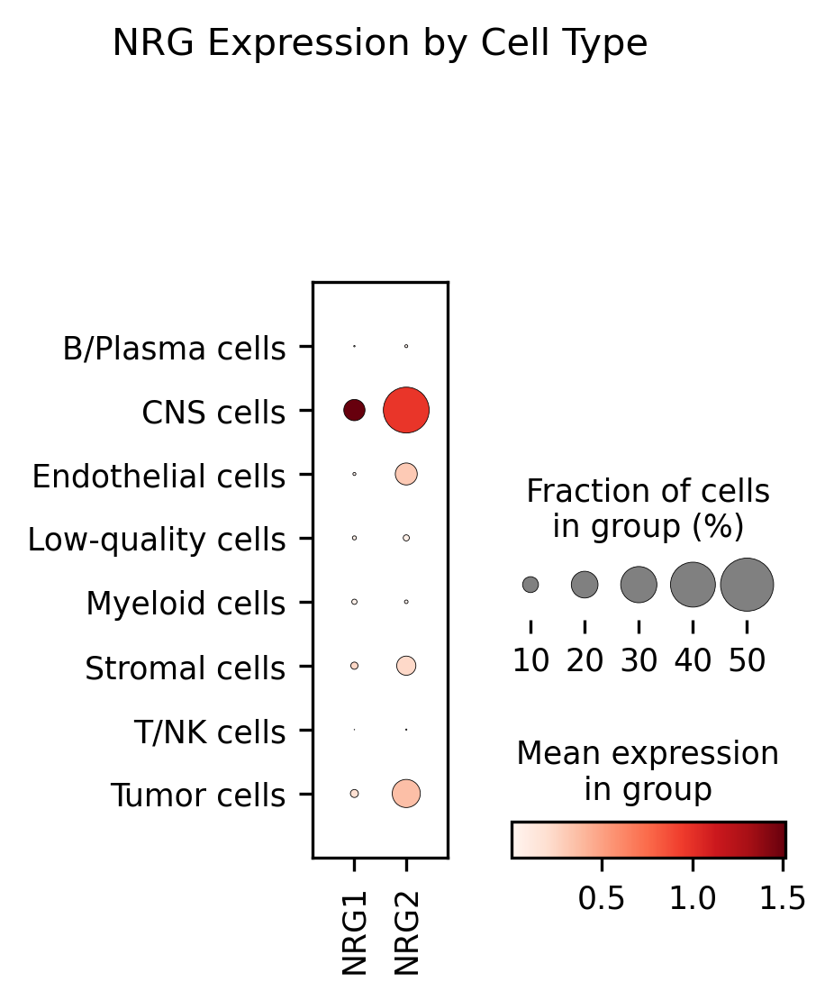

In [83]:
sc.pl.dotplot(adata[(adata.obs.organ == "Brain")], 
              var_names = ["NRG1", "NRG2"],
              #gene_symbols = "gene_ids",
              groupby = 'cell_type_main',
              #log = True,
              #vmin = 2.25,
              #vmax = 2.5,
              dendrogram = False,
              title = f'NRG Expression by Cell Type',)
              #save='Tsoi_louvain.png')

# Fig. 5E

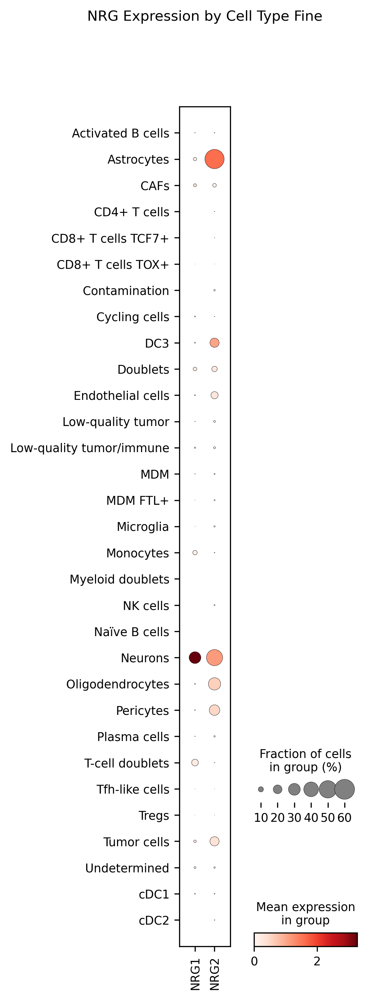

In [82]:
sc.pl.dotplot(adata[(adata.obs.organ == "Brain")], 
              var_names = ["NRG1", "NRG2"],
              #gene_symbols = "gene_ids",
              groupby = 'cell_type_fine',
              #log = True,
              #vmin = 2.25,
              #vmax = 2.5,
              dendrogram = False,
              title = f'NRG Expression by Cell Type Fine',)
              #save='Tsoi_louvain.png')

## ERBB3 Expression in malignant cells

In [35]:
adata[(adata.obs.malignant == "malignant")].obs

,orig.ident,barcode,barcode_pat,patient,ID,batch,sequencing,organ,doublet_scores,doublet,...,disease_TRB3,tcr,both_chains,mait,inkt,mait_inkt,clone_size,n_genes,percent_mito,n_counts
Cell,,,,,,,,,,,,,,,,,,,,,
CGTTGGGGTGTTAAGA-1_1,MBM01_sc_CD45pos,CGTTGGGGTGTTAAGA-1,CGTTGGGGTGTTAAGA-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.028748,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,6994,0.058182,39428.0
GGAGCAAGTTTGGGCC-1_1,MBM01_sc_CD45pos,GGAGCAAGTTTGGGCC-1,GGAGCAAGTTTGGGCC-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.112922,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,6809,0.091809,39408.0
TGGGCGTCATTGGCGC-1_1,MBM01_sc_CD45pos,TGGGCGTCATTGGCGC-1,TGGGCGTCATTGGCGC-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.128695,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,6848,0.081938,39225.0
CGATGGCAGAGAGCTC-1_1,MBM01_sc_CD45pos,CGATGGCAGAGAGCTC-1,CGATGGCAGAGAGCTC-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.044448,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,6544,0.066557,36570.0
CCGTGGAAGCTTTGGT-1_1,MBM01_sc_CD45pos,CCGTGGAAGCTTTGGT-1,CCGTGGAAGCTTTGGT-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.015947,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,6862,0.066791,36037.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TACTGCCCATCGAGCC-1_32,MPM11_sn,TACTGCCCATCGAGCC-1,TACTGCCCATCGAGCC-1_MPM11_sn,MPM11_sn,MPM11,NaN,Single nuclei,Peripheral,0.060541,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,770,0.060914,1182.0
GCACGTGTCGTAATGC-1_32,MPM11_sn,GCACGTGTCGTAATGC-1,GCACGTGTCGTAATGC-1_MPM11_sn,MPM11_sn,MPM11,NaN,Single nuclei,Peripheral,0.033597,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,718,0.053010,1113.0
ATGGAGGAGTTTGTCG-1_32,MPM11_sn,ATGGAGGAGTTTGTCG-1,ATGGAGGAGTTTGTCG-1_MPM11_sn,MPM11_sn,MPM11,NaN,Single nuclei,Peripheral,0.052060,Singlet,...,NaN,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,862,0.030035,1132.0


# Fig. 4E

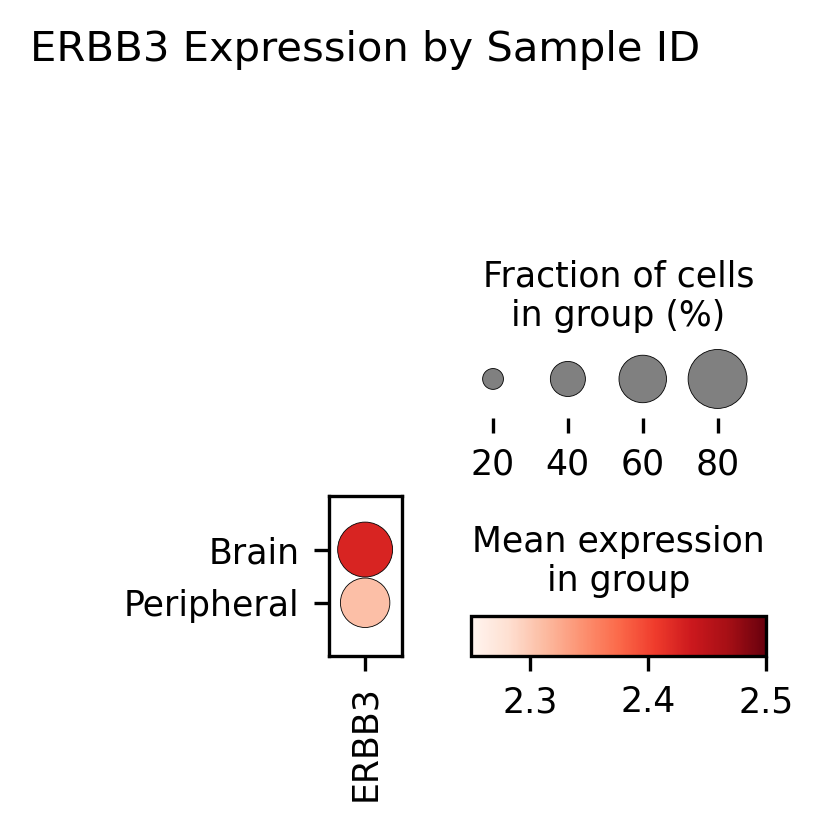

In [36]:
sc.pl.dotplot(adata[(adata.obs.malignant == "malignant")], 
              var_names = "ERBB3",
              #gene_symbols = "gene_ids",
              groupby = 'organ',
              #log = True,
              vmin = 2.25,
              vmax = 2.5,
              dendrogram = False,
              title = f'ERBB3 Expression by Sample ID',)
              #save='Tsoi_louvain.png')

## Cell2Cell - MBM samples

In [37]:
# Load list of Ligand-Receptro pairs published with CellChat (Jin et al. 2021, Nature Communications)
lr_pairs = pd.read_csv('https://raw.githubusercontent.com/LewisLabUCSD/Ligand-Receptor-Pairs/master/Human/Human-2020-Jin-LR-pairs.csv')
lr_pairs = lr_pairs.astype(str)

In [38]:
lr_pairs.head()

,interaction_name,pathway_name,ligand,receptor,agonist,antagonist,co_A_receptor,co_I_receptor,evidence,annotation,interaction_name_2,ligand_symbol,receptor_symbol,ligand_ensembl,receptor_ensembl,interaction_symbol,interaction_ensembl
0,TGFB1_TGFBR1_TGFBR2,TGFb,TGFB1,TGFbR1_R2,TGFb agonist,TGFb antagonist,nan,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,TGFB1 - (TGFBR1+TGFBR2),TGFB1,TGFBR1&TGFBR2,ENSG00000105329,ENSG00000106799&ENSG00000163513,TGFB1^TGFBR1&TGFBR2,ENSG00000105329^ENSG00000106799&ENSG00000163513
1,TGFB2_TGFBR1_TGFBR2,TGFb,TGFB2,TGFbR1_R2,TGFb agonist,TGFb antagonist,nan,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,TGFB2 - (TGFBR1+TGFBR2),TGFB2,TGFBR1&TGFBR2,ENSG00000092969,ENSG00000106799&ENSG00000163513,TGFB2^TGFBR1&TGFBR2,ENSG00000092969^ENSG00000106799&ENSG00000163513
2,TGFB3_TGFBR1_TGFBR2,TGFb,TGFB3,TGFbR1_R2,TGFb agonist,TGFb antagonist,nan,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,TGFB3 - (TGFBR1+TGFBR2),TGFB3,TGFBR1&TGFBR2,ENSG00000119699,ENSG00000106799&ENSG00000163513,TGFB3^TGFBR1&TGFBR2,ENSG00000119699^ENSG00000106799&ENSG00000163513
3,TGFB1_ACVR1B_TGFBR2,TGFb,TGFB1,ACVR1B_TGFbR2,TGFb agonist,TGFb antagonist,nan,TGFb inhibition receptor,PMID: 27449815,Secreted Signaling,TGFB1 - (ACVR1B+TGFBR2),TGFB1,ACVR1B&TGFBR2,ENSG00000105329,ENSG00000135503&ENSG00000163513,TGFB1^ACVR1B&TGFBR2,ENSG00000105329^ENSG00000135503&ENSG00000163513
4,TGFB1_ACVR1C_TGFBR2,TGFb,TGFB1,ACVR1C_TGFbR2,TGFb agonist,TGFb antagonist,nan,TGFb inhibition receptor,PMID: 27449815,Secreted Signaling,TGFB1 - (ACVR1C+TGFBR2),TGFB1,ACVR1C&TGFBR2,ENSG00000105329,ENSG00000123612&ENSG00000163513,TGFB1^ACVR1C&TGFBR2,ENSG00000105329^ENSG00000123612&ENSG00000163513


In [39]:
c2c_meta_MBM = adata[(adata.obs.organ == "Brain")].obs.copy()
c2c_meta_MBM['index'] = c2c_meta_MBM.index
c2c_meta_MBM

,orig.ident,barcode,barcode_pat,patient,ID,batch,sequencing,organ,doublet_scores,doublet,...,tcr,both_chains,mait,inkt,mait_inkt,clone_size,n_genes,percent_mito,n_counts,index
Cell,,,,,,,,,,,,,,,,,,,,,
CTCGTACCAAGCTGGA-1_1,MBM01_sc_CD45pos,CTCGTACCAAGCTGGA-1,CTCGTACCAAGCTGGA-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.048314,Singlet,...,TCR,both,no_MAIT,no_iNKT,no_MAIT;no_iNKT,Non-expanded,4018,0.007060,59917.0,CTCGTACCAAGCTGGA-1_1
AGATTGCAGTGGGTTG-1_1,MBM01_sc_CD45pos,AGATTGCAGTGGGTTG-1,AGATTGCAGTGGGTTG-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.046330,Singlet,...,TCR,both,no_MAIT,no_iNKT,no_MAIT;no_iNKT,Non-expanded,4269,0.008102,59248.0,AGATTGCAGTGGGTTG-1_1
TACACGATCAACACAC-1_1,MBM01_sc_CD45pos,TACACGATCAACACAC-1,TACACGATCAACACAC-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.106180,Singlet,...,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,5452,0.011169,59004.0,TACACGATCAACACAC-1_1
GACCAATTCGCCAGCA-1_1,MBM01_sc_CD45pos,GACCAATTCGCCAGCA-1,GACCAATTCGCCAGCA-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.100060,Singlet,...,TCR,both,no_MAIT,no_iNKT,no_MAIT;no_iNKT,Non-expanded,4919,0.008414,58239.0,GACCAATTCGCCAGCA-1_1
TACTTGTCAATAGCAA-1_1,MBM01_sc_CD45pos,TACTTGTCAATAGCAA-1,TACTTGTCAATAGCAA-1_MBM01_sc_CD45pos,MBM01_sc,MBM01,CD45pos,Single cells,Brain,0.046330,Singlet,...,TCR,both,no_MAIT,no_iNKT,no_MAIT;no_iNKT,Expanded,4185,0.011597,57947.0,TACTTGTCAATAGCAA-1_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCTTGCGTCGATCCCT-1_22,MBM21_sn,TCTTGCGTCGATCCCT-1,TCTTGCGTCGATCCCT-1_MBM21_sn,MBM21_sn,MBM21,NaN,Single nuclei,Brain,0.026988,Singlet,...,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,734,0.013725,1020.0,TCTTGCGTCGATCCCT-1_22
ACAAGCTCACCGGAAA-1_22,MBM21_sn,ACAAGCTCACCGGAAA-1,ACAAGCTCACCGGAAA-1_MBM21_sn,MBM21_sn,MBM21,NaN,Single nuclei,Brain,0.033196,Singlet,...,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,692,0.021611,1018.0,ACAAGCTCACCGGAAA-1_22
CAAAGAACATAGTCAC-1_22,MBM21_sn,CAAAGAACATAGTCAC-1,CAAAGAACATAGTCAC-1_MBM21_sn,MBM21_sn,MBM21,NaN,Single nuclei,Brain,0.036348,Singlet,...,no_TCR,NaN,no_MAIT,no_iNKT,no_MAIT;no_iNKT,NaN,720,0.000997,1003.0,CAAAGAACATAGTCAC-1_22


In [40]:
interactions_MBM = c2c.analysis.SingleCellInteractions(rnaseq_data=adata[(adata.obs.organ == "Brain")].to_df().T,
                                                   ppi_data=lr_pairs,
                                                   metadata=c2c_meta_MBM,
                                                   interaction_columns=('ligand_symbol', 'receptor_symbol'),
                                                   communication_score='expression_thresholding',
                                                   expression_threshold=0.1, # values after aggregation
                                                   cci_score='bray_curtis',
                                                   cci_type='undirected',
                                                   aggregation_method='nn_cell_fraction',
                                                   barcode_col='index',
                                                   celltype_col='cell_type_fine',
                                                   complex_sep='&',
                                                   verbose=False)

In [41]:
interactions_MBM.compute_pairwise_communication_scores()

Computing pairwise communication
Computing communication score between MDM and CD8+ T cells TOX+
Computing communication score between Monocytes and Tregs
Computing communication score between Activated B cells and Plasma cells
Computing communication score between CAFs and cDC1
Computing communication score between MDM FTL+ and MDM FTL+
Computing communication score between Astrocytes and Tfh-like cells
Computing communication score between Activated B cells and CAFs
Computing communication score between CD8+ T cells TCF7+ and DC3
Computing communication score between Contamination and DC3
Computing communication score between Naïve B cells and Low-quality tumor
Computing communication score between Myeloid doublets and CD8+ T cells TOX+
Computing communication score between CD8+ T cells TOX+ and CAFs
Computing communication score between Neurons and Monocytes
Computing communication score between Cycling cells and T-cell doublets
Computing communication score between NK cells and MDM

In [42]:
interactions_MBM.compute_pairwise_cci_scores()

Computing pairwise interactions
Computing interaction score between Monocytes and Tregs
Computing interaction score between Activated B cells and Plasma cells
Computing interaction score between CAFs and cDC1
Computing interaction score between MDM FTL+ and MDM FTL+
Computing interaction score between Astrocytes and Tfh-like cells
Computing interaction score between Activated B cells and CAFs
Computing interaction score between CD8+ T cells TCF7+ and DC3
Computing interaction score between Contamination and DC3
Computing interaction score between Cycling cells and T-cell doublets
Computing interaction score between Astrocytes and Naïve B cells
Computing interaction score between Activated B cells and Doublets
Computing interaction score between CAFs and Tregs
Computing interaction score between MDM and cDC2
Computing interaction score between Endothelial cells and MDM FTL+
Computing interaction score between Oligodendrocytes and Tregs
Computing interaction score between NK cells and Tr

In [43]:
cci_pvals_MBM = interactions_MBM.permute_cell_labels(evaluation='interactions', 
                                             permutations=1000, 
                                             fdr_correction=True,
                                             verbose=True)

100%|██████████████████████████████████████████████████| 1000/1000 [4:46:15<00:00, 17.18s/it]


In [44]:
cci_pvals_MBM

,Activated B cells,Astrocytes,CAFs,CD4+ T cells,CD8+ T cells TCF7+,CD8+ T cells TOX+,Contamination,Cycling cells,DC3,Doublets,...,Oligodendrocytes,Pericytes,Plasma cells,T-cell doublets,Tfh-like cells,Tregs,Tumor cells,Undetermined,cDC1,cDC2
Activated B cells,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
Astrocytes,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.115478,...,0.040493,0.050930,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
CAFs,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.004337,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
CD4+ T cells,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
CD8+ T cells TCF7+,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
CD8+ T cells TOX+,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
Contamination,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
Cycling cells,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.858338,0.002178,0.021450,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.577069,0.002178,0.067617
DC3,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,...,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178,0.002178
Doublets,0.002178,0.115478,0.004337,0.002178,0.002178,0.002178,0.002178,0.021450,0.002178,0.002178,...,0.002178,0.577919,0.002178,0.002178,0.002178,0.002178,0.002178,0.991009,0.002178,0.002178


In [45]:
ccc_pvals_MBM = interactions_MBM.permute_cell_labels(evaluation='communication',
                                             permutations=1000, 
                                             fdr_correction=True,
                                             verbose=True)

100%|██████████████████████████████████████████████████| 1000/1000 [5:52:53<00:00, 21.17s/it]


In [46]:
ccc_pvals_MBM

,MDM;CD8+ T cells TOX+,Monocytes;Tregs,Activated B cells;Plasma cells,CAFs;cDC1,MDM FTL+;MDM FTL+,Astrocytes;Tfh-like cells,Activated B cells;CAFs,CD8+ T cells TCF7+;DC3,Contamination;DC3,Naïve B cells;Low-quality tumor,...,Doublets;MDM,Endothelial cells;Neurons,Neurons;DC3,Neurons;Myeloid doublets,Tregs;Plasma cells,Tumor cells;MDM FTL+,T-cell doublets;CAFs,MDM;cDC1,cDC2;Monocytes,Doublets;Activated B cells
"(TGFB1, TGFBR1&TGFBR2)",0.051826,0.051826,0.051826,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,1.000000,...,1.000000,0.051826,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,1.000000,0.051826
"(TGFB2, TGFBR1&TGFBR2)",1.000000,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.051826,0.051826,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
"(TGFB3, TGFBR1&TGFBR2)",1.000000,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
"(TGFB1, ACVR1B&TGFBR2)",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
"(TGFB1, ACVR1C&TGFBR2)",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"(THY1, ITGAV&ITGB3)",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
"(ITGA4&ITGB1, VCAM1)",0.051826,1.000000,1.000000,0.051826,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,...,0.051826,1.000000,1.000000,1.000000,1.000000,1.000000,0.051826,0.051826,1.000000,1.000000
"(ITGA9&ITGB1, VCAM1)",0.051826,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.051826,1.000000,1.000000,0.229896,1.000000,1.000000,1.000000,0.051826,1.000000,1.000000
"(ITGA4&ITGB7, VCAM1)",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.051826,1.000000,1.000000,1.000000,...,0.051826,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [47]:
c2c_meta_MBM.cell_type_fine.unique()

['Plasma cells', 'Doublets', 'Cycling cells', 'Undetermined', 'cDC1', ..., 'Astrocytes', 'Low-quality tumor/immune', 'Neurons', 'Contamination', 'Pericytes']
Length: 31
Categories (31, object): ['Activated B cells', 'Astrocytes', 'CAFs', 'CD4+ T cells', ..., 'Tumor cells', 'Undetermined', 'cDC1', 'cDC2']

In [48]:
group_meta_MBM = pd.DataFrame(columns=['cell_type_fine', 'cell_type_main'])
group_meta_MBM['cell_type_fine'] = c2c_meta_MBM.cell_type_fine.unique().tolist()
group_meta_MBM['cell_type_main'] = dict(zip(c2c_meta_MBM.cell_type_fine, c2c_meta_MBM.cell_type_main)).values()

In [105]:
np.unique(group_meta_MBM['cell_type_fine'])

array(['Activated B cells', 'Astrocytes', 'CAFs', 'CD4+ T cells',
       'CD8+ T cells TCF7+', 'CD8+ T cells TOX+', 'Contamination',
       'Cycling cells', 'DC3', 'Doublets', 'Endothelial cells',
       'Low-quality tumor', 'Low-quality tumor/immune', 'MDM', 'MDM FTL+',
       'Microglia', 'Monocytes', 'Myeloid doublets', 'NK cells',
       'Naïve B cells', 'Neurons', 'Oligodendrocytes', 'Pericytes',
       'Plasma cells', 'T-cell doublets', 'Tfh-like cells', 'Tregs',
       'Tumor cells', 'Undetermined', 'cDC1', 'cDC2'], dtype=object)

In [49]:
colors_MBM = c2c.plotting.get_colors_from_labels(labels=group_meta_MBM['cell_type_main'].unique().tolist(),
                                             cmap='tab10'
                                            )

In [53]:
sender_cells_MBM = ['Neurons', 'Astrocytes', 'Pericytes', 'Microglia']
receiver_cells_MBM = ['Tumor cells']
ligands_MBM = ['NRG1',
           'NRG2',
           'NRG3',
           'NRG4'
          ]
receptors_MBM = ['ERBB3'
            ]

# Fig. 5F

<Axes:>

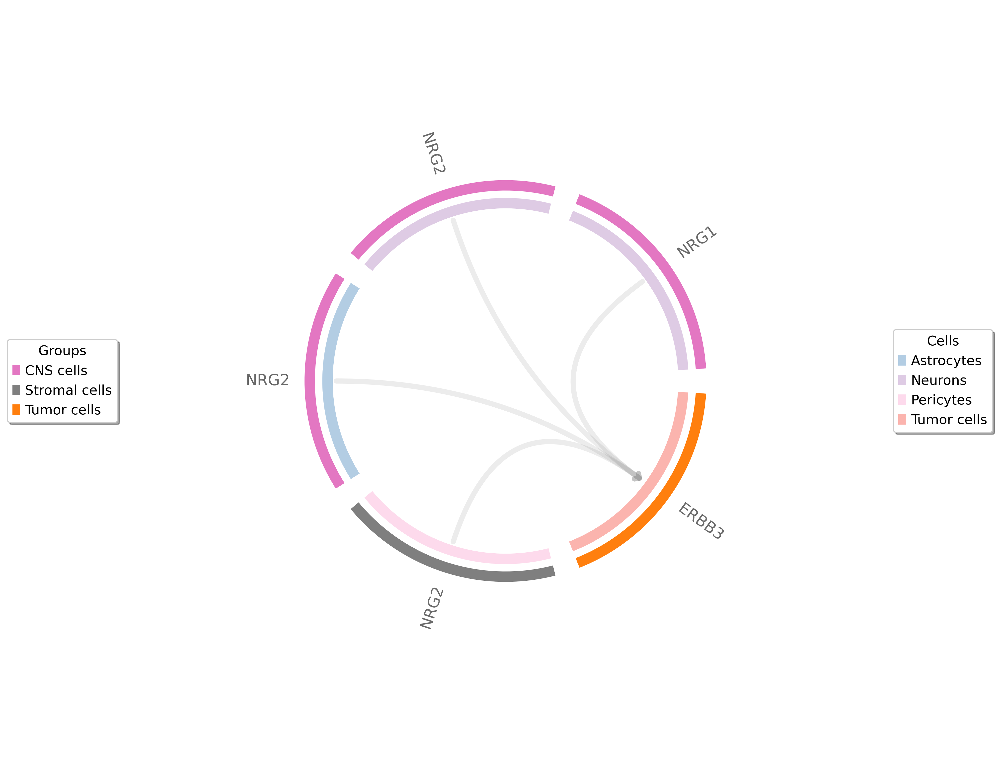

In [54]:
c2c.plotting.circos_plot(interaction_space=interactions_MBM,
                         sender_cells=sender_cells_MBM,
                         receiver_cells=receiver_cells_MBM,
                         ligands=ligands_MBM,
                         receptors=receptors_MBM,
                         excluded_score=0,
                         metadata=group_meta_MBM,
                         sample_col='cell_type_fine',
                         group_col='cell_type_main',
                         colors=colors_MBM,
                         fontsize=15,
                        )

# Fig. 5A

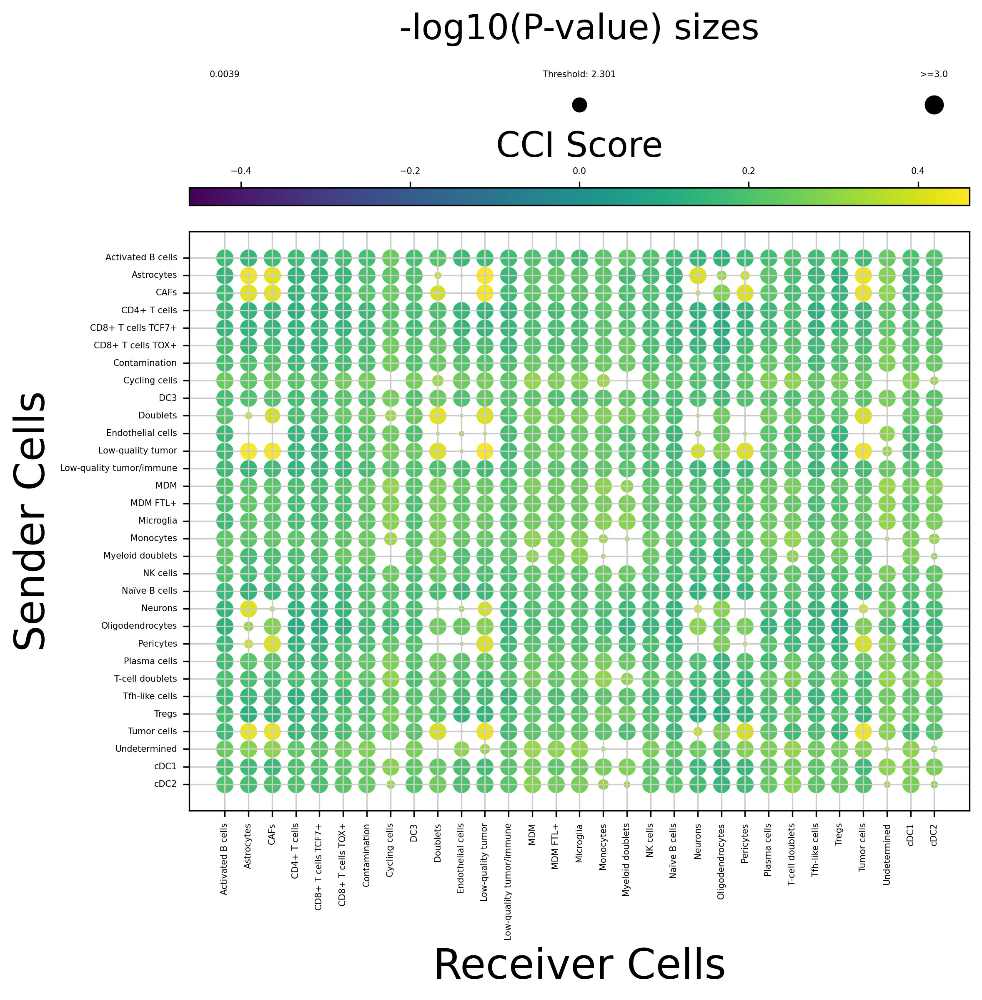

In [98]:
fig_MBM = c2c.plotting.dot_plot(interactions_MBM,
                            evaluation='interactions',
                            significance = 0.005,
                            #senders = sender_cells_MBM,
                            #receivers  = receiver_cells_MBM,
                            figsize=(8, 8),
                            tick_size = 5,
                            cmap='viridis',
                            )

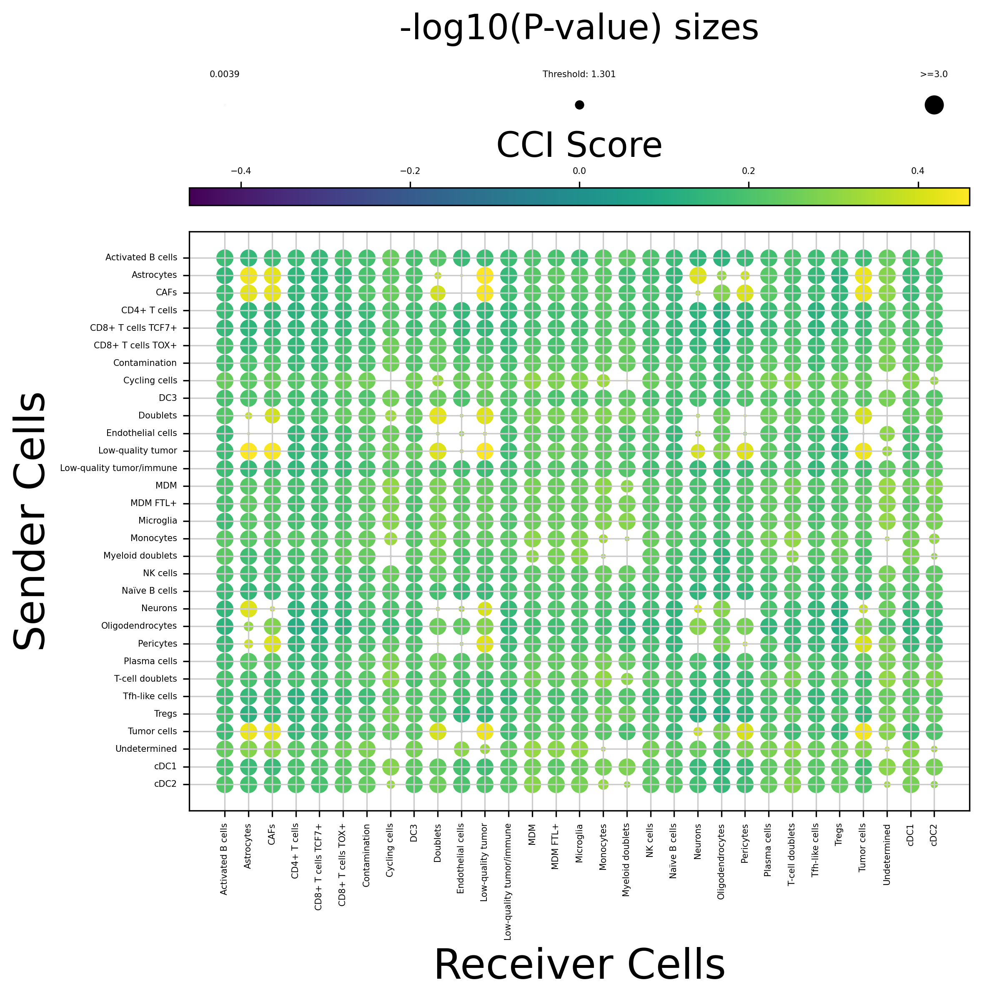

In [103]:
fig_MBM = c2c.plotting.dot_plot(interactions_MBM,
                            evaluation='interactions',
                            significance = 0.05,
                            #senders = sender_cells_MBM,
                            #receivers  = receiver_cells_MBM,
                            figsize=(8, 8),
                            tick_size = 5,
                            cmap='viridis',
                            )

In [112]:
sender_cells_MBM = ['Neurons', 'Astrocytes', 'Pericytes', 'Tumor cells', 'CAFs', 'Low-quality tumor', 'Oligodendrocytes']
receiver_cells_MBM = ['Neurons', 'Astrocytes', 'Pericytes', 'Tumor cells', 'CAFs', 'Low-quality tumor', 'Oligodendrocytes']

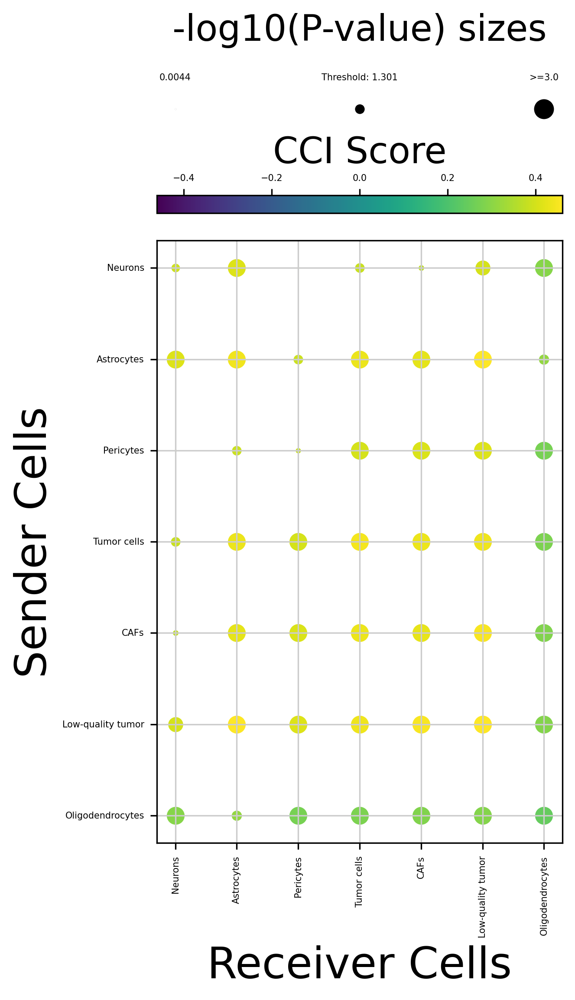

In [113]:
fig_MBM = c2c.plotting.dot_plot(interactions_MBM,
                            evaluation='interactions',
                            significance = 0.05,
                            senders = sender_cells_MBM,
                            receivers  = receiver_cells_MBM,
                            figsize=(4, 8),
                            tick_size = 5,
                            cmap='viridis',
                            )

In [116]:
colors = c2c.plotting.get_colors_from_labels(labels=group_meta_MBM['cell_type_main'].unique().tolist(),
                                             cmap='tab10'
                                            )

Interaction space detected as a Interactions class


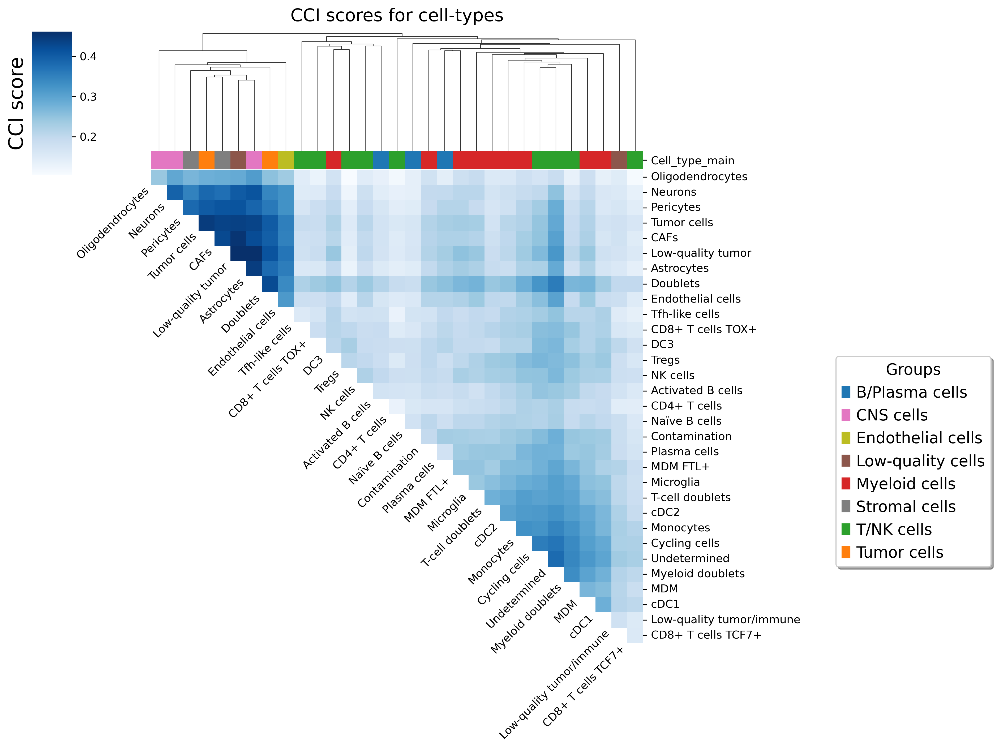

In [117]:
cm = c2c.plotting.clustermap_cci(interactions_MBM,
                                 method='complete',
                                 metadata=group_meta_MBM,
                                 sample_col="cell_type_fine",
                                 group_col="cell_type_main",
                                 colors=colors,
                                 title='CCI scores for cell-types',
                                 cmap='Blues'
                                 )

# Add a legend to know the groups of the sender and receiver cells:
l1 = c2c.plotting.generate_legend(color_dict=colors,
                                  loc='center left',
                                  bbox_to_anchor=(20, -2), # Indicated where to include it
                                  ncol=1, fancybox=True,
                                  shadow=True,
                                  title='Groups',
                                  fontsize=14,
                                 )

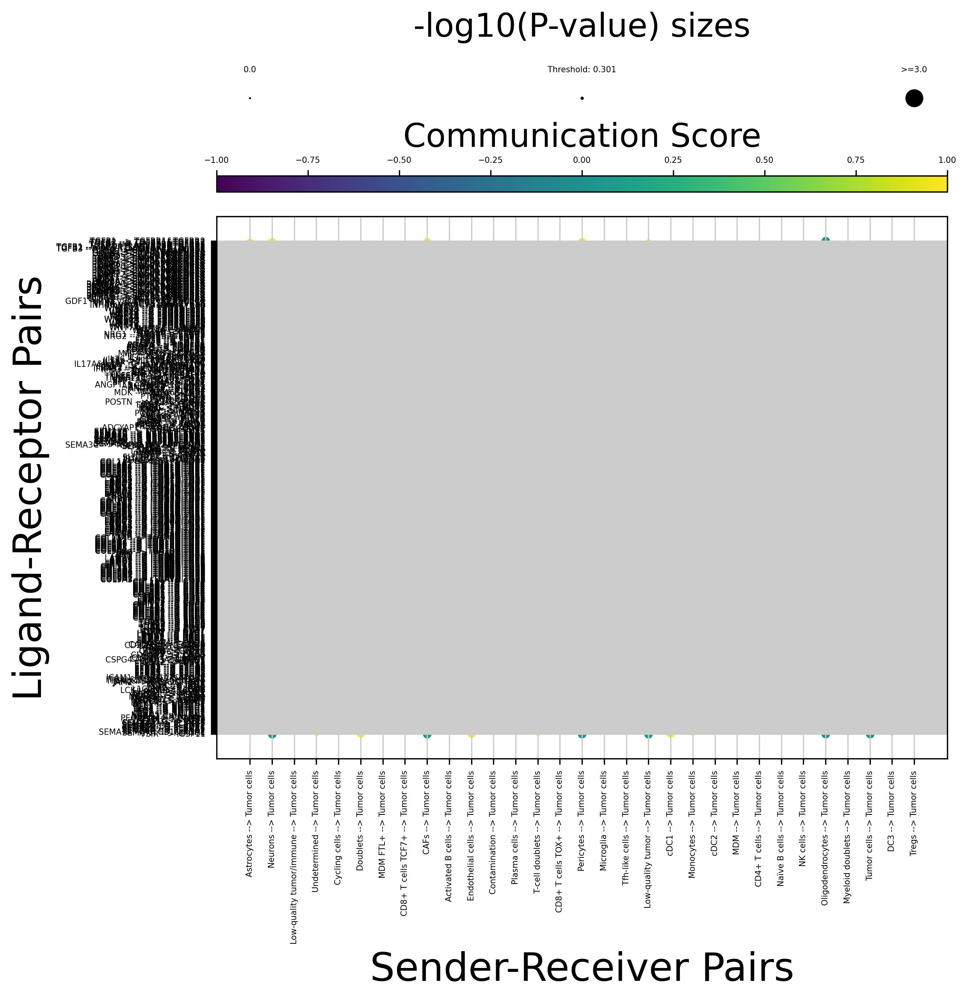

In [92]:
fig_MBM = c2c.plotting.dot_plot(interactions_MBM,
                            evaluation='communication',
                            significance = 0.5,
                            #senders = sender_cells_MBM,
                            receivers  = receiver_cells_MBM,
                            figsize=(8, 8),
                            tick_size = 5,
                            cmap='viridis',
                            )

# Fig. 5B

Interaction space detected as a Interactions class


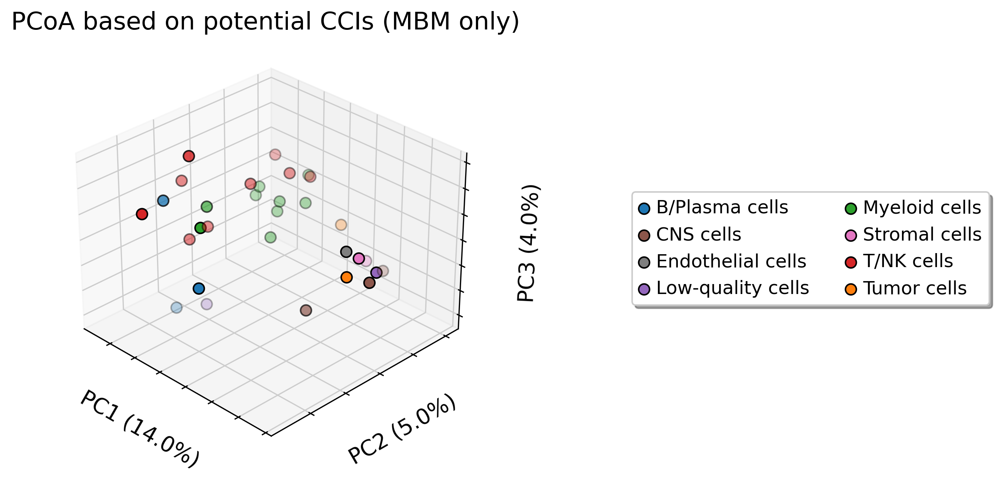

In [65]:
if interactions_MBM.analysis_setup['cci_type'] == 'undirected':
        
    pcoa_MBM = c2c.plotting.pcoa_3dplot(interactions_MBM,
                                    metadata=group_meta_MBM,
                                    sample_col="cell_type_fine",
                                    group_col="cell_type_main",
                                    title='PCoA based on potential CCIs (MBM only)',
                                    colors=colors,
                                    )

In [94]:
# generate N distinct colours (excluding black and white by default)
distinct_colors = distinctipy.get_colors(len(meta['cell_type_fine'].unique().tolist()))

# display the colours
#distinctipy.color_swatch(distinct_colors)

In [95]:
celltype_colors_MBM_distinct = {}
for i, celltype in enumerate((meta['cell_type_fine'].unique().tolist())):
    celltype_colors_MBM_distinct[celltype] = distinct_colors[i]

# Fig. 5C

Interaction space detected as a Interactions class


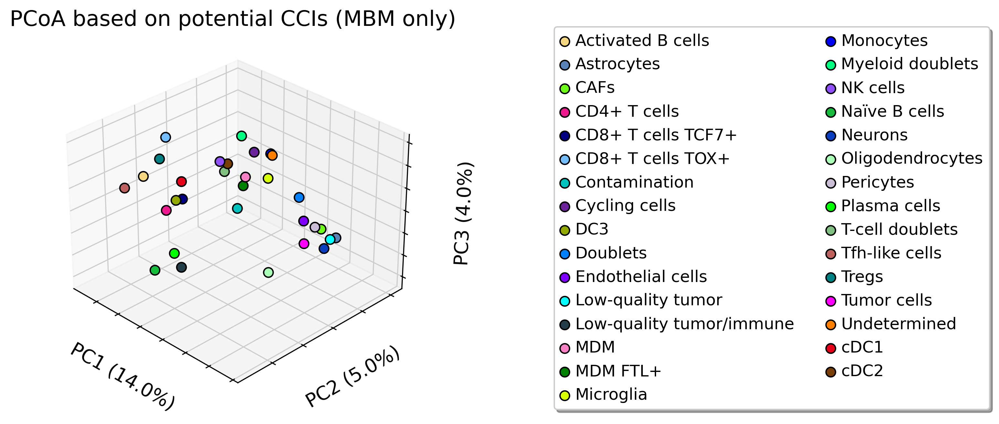

In [96]:
if interactions_MBM.analysis_setup['cci_type'] == 'undirected':
    celltype_colors_MBM = c2c.plotting.get_colors_from_labels(labels=meta['cell_type_fine'].unique().tolist(),
                                                          cmap='tab20'
                                                         )    
    pcoa_MBM = c2c.plotting.pcoa_3dplot(interactions_MBM,
                                    title='PCoA based on potential CCIs (MBM only)',
                                    colors=celltype_colors_MBM_distinct,
                                    )